In [5]:
import os
import glob
import subprocess
import sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q","pandas", "numpy", "pyarrow", "matplotlib", "seaborn","kagglehub"], check=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

PARQUET_FILE="cleaned_accidents.parquet"
if os.path.exists(PARQUET_FILE):
    df=pd.read_parquet(PARQUET_FILE)
else:
    dataset_dir=kagglehub.dataset_download("sobhanmoosavi/us-accidents")
    csv_files=glob.glob(os.path.join(dataset_dir, "*.csv"))
    if not csv_files:
        raise FileNotFoundError("No CSV dataset found.")

    csv_file=max(csv_files, key=os.path.getsize)
    columns=["ID", "Severity", "Start_Time", "End_Time", "Start_Lat", "Start_Lng", "Street", "County", "State"]
    df=pd.read_csv(csv_file, usecols=columns,engine="pyarrow")
    for col in ["Start_Time", "End_Time"]:
        df[col]=pd.to_datetime(df[col], errors="coerce")
    df["Severity"]=pd.to_numeric(df["Severity"], errors="coerce")
    df=df.dropna(subset=["ID", "Severity", "Start_Time", "End_Time", "Start_Lat", "Start_Lng", "Street", "County", "State"]).copy()
    df=df[df["Start_Lat"].between(24, 50)&df["Start_Lng"].between(-125, -66)].copy()
    df["Duration_Mins"]=((df["End_Time"] - df["Start_Time"]).dt.total_seconds()/60)
    df=df[df["Duration_Mins"].between(0, 1440, inclusive="neither")].copy()
    df["County"]=df["County"].astype("string").str.strip()
    df["State"]=df["State"].astype("string").str.strip()
    df["Street"]=df["Street"].astype("string").str.strip().str.title()
    df.to_parquet(PARQUET_FILE, index=False, compression="snappy")

print(f"Dataset loaded: {len(df):,} records")
print(f"Columns: {list(df.columns)}")


Dataset loaded: 7,682,439 records
Columns: ['ID', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'Street', 'County', 'State', 'Duration_Mins']


In [6]:
print("Available states:")
print(", ".join(sorted(df["State"].dropna().unique())))

county_input=input("Enter county name: ").strip()
state_input=input("Enter state code (optional, e.g. CA, TX): ").strip()

mask=df["County"].str.casefold()==county_input.casefold()

if state_input:
    mask&=df["State"].str.upper()==state_input.upper()
county_df=df.loc[mask].copy()

if county_df.empty:
    print("No records found. Check the county and state names.")

else:
    print(f"\nRecords found: {len(county_df):,}")
    print("Matching locations:")
    print(county_df[["County", "State"]].drop_duplicates().to_string(index=False))
    display(county_df.head(20))

Available states:
AL, AR, AZ, CA, CO, CT, DC, DE, FL, GA, IA, ID, IL, IN, KS, KY, LA, MA, MD, ME, MI, MN, MO, MS, MT, NC, ND, NE, NH, NJ, NM, NV, NY, OH, OK, OR, PA, RI, SC, SD, TN, TX, UT, VA, VT, WA, WI, WV, WY
Enter county name: Los Angeles
Enter state code (optional, e.g. CA, TX): CA

Records found: 525,831
Matching locations:
     County State
Los Angeles    CA


,ID,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Street,County,State,Duration_Mins
42864,A-42865,3,2016-06-21 10:44:51,2016-06-21 11:24:00,34.321411,-118.496750,I-5 N,Los Angeles,CA,39.150000
42865,A-42866,2,2016-06-21 10:44:12,2016-06-21 11:22:00,34.146858,-118.370384,Ca-170 S,Los Angeles,CA,37.800000
42866,A-42867,2,2016-06-21 10:46:30,2016-06-21 11:27:00,34.078926,-118.289040,Us-101 N,Los Angeles,CA,40.500000
42867,A-42868,3,2016-06-21 10:49:21,2016-06-21 11:34:21,34.091179,-118.239471,Golden State Fwy S,Los Angeles,CA,45.000000
42868,A-42869,3,2016-06-21 10:46:04,2016-06-21 11:31:04,34.207294,-118.216927,Foothill Fwy E,Los Angeles,CA,45.000000
42869,A-42870,2,2016-06-21 10:43:39,2016-06-21 11:28:39,34.041412,-118.064323,Pomona Fwy W,Los Angeles,CA,45.000000
42870,A-42871,3,2016-06-21 10:45:30,2016-06-21 11:30:30,34.054359,-118.004349,Valley Blvd,Los Angeles,CA,45.000000
42873,A-42874,2,2016-06-21 08:55:56,2016-06-21 11:09:00,34.024540,-117.740852,Pomona Fwy W,Los Angeles,CA,133.066667
42879,A-42880,3,2016-06-21 10:50:48,2016-06-21 11:35:48,34.339706,-118.506447,Ca-14 N,Los Angeles,CA,45.000000
42880,A-42881,3,2016-06-21 10:51:15,2016-06-21 11:36:15,33.945335,-118.368263,W Century Blvd,Los Angeles,CA,45.000000


In [9]:
if not county_df.empty:
    print("Dataset Information: ")
    county_df.info()
    print("Missing Values: ")
    print(county_df.isna().sum())
    print("Descriptive Statistics: ")
    display(county_df.describe(include="all").T)
    print("Accident Severity Distribution: ")
    display(county_df["Severity"].value_counts().sort_index().rename_axis("Severity").to_frame("Incidents"))
    print("Top 10 Streets by Accident Count: ")
    display(county_df.groupby("Street", observed=True).size().sort_values(ascending=False).head(10).rename("Incidents").to_frame())
    print("Accident Duration Statistics: ")
    display(county_df["Duration_Mins"].describe().to_frame("Duration (minutes)"))
    print("Accidents by Year: ")
    display(county_df.groupby(county_df["Start_Time"].dt.year).size().rename("Incidents").to_frame())

Dataset Information: 
<class 'pandas.core.frame.DataFrame'>
Index: 525831 entries, 42864 to 7682437
Data columns (total 14 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   ID             525831 non-null  object        
 1   Severity       525831 non-null  int64         
 2   Start_Time     525831 non-null  datetime64[ns]
 3   End_Time       525831 non-null  datetime64[ns]
 4   Start_Lat      525831 non-null  float64       
 5   Start_Lng      525831 non-null  float64       
 6   Street         525831 non-null  string        
 7   County         525831 non-null  string        
 8   State          525831 non-null  string        
 9   Duration_Mins  525831 non-null  float64       
 10  Hour           525831 non-null  int32         
 11  Year           525831 non-null  int32         
 12  Month          525831 non-null  int32         
 13  Weekday        525831 non-null  object        
dtypes: datetime64[ns](2), float64(

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ID,525831,525831,A-7777760,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Severity,525831.0,NaN,NaN,NaN,2.229159,1.0,2.0,2.0,2.0,4.0,0.440127
Start_Time,525831,NaN,NaN,NaN,2020-02-27 09:10:38.248018688,2016-03-22 19:14:41,2018-06-19 15:54:13,2020-05-20 19:03:40,2021-12-07 05:27:15,2023-03-31 21:53:30,NaN
End_Time,525831,NaN,NaN,NaN,2020-02-27 11:07:29.512300032,2016-03-22 22:23:42,2018-06-19 17:09:47,2020-05-20 20:12:36,2021-12-07 06:20:45,2023-03-31 23:58:00,NaN
Start_Lat,525831.0,NaN,NaN,NaN,34.059435,33.711548,33.960007,34.036655,34.134101,34.82074,0.158933
Start_Lng,525831.0,NaN,NaN,NaN,-118.212676,-119.012195,-118.34526,-118.226384,-118.091896,-117.653125,0.203278
Street,525831,8818,I-405 N,20355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
County,525831,1,Los Angeles,525831,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,525831,1,CA,525831,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Duration_Mins,525831.0,NaN,NaN,NaN,116.854405,3.0,32.916667,62.083333,131.266667,1438.433333,137.867523


Accident Severity Distribution: 


,Incidents
Severity,
1,831
2,407326
3,114018
4,3656


Top 10 Streets by Accident Count: 


,Incidents
Street,
I-405 N,20355
I-10 E,19615
I-10 W,17901
Golden State Fwy S,14271
I-405 S,11777
I-605 S,10830
Foothill Fwy E,10425
I-5 N,10129
Foothill Fwy W,9739


Accident Duration Statistics: 


,Duration (minutes)
count,525831.000000
mean,116.854405
std,137.867523
min,3.000000
25%,32.916667
50%,62.083333
75%,131.266667
max,1438.433333


Accidents by Year: 


,Incidents
Start_Time,
2016,51929
2017,52975
2018,55296
2019,67170
2020,80774
2021,94514
2022,103118
2023,20055


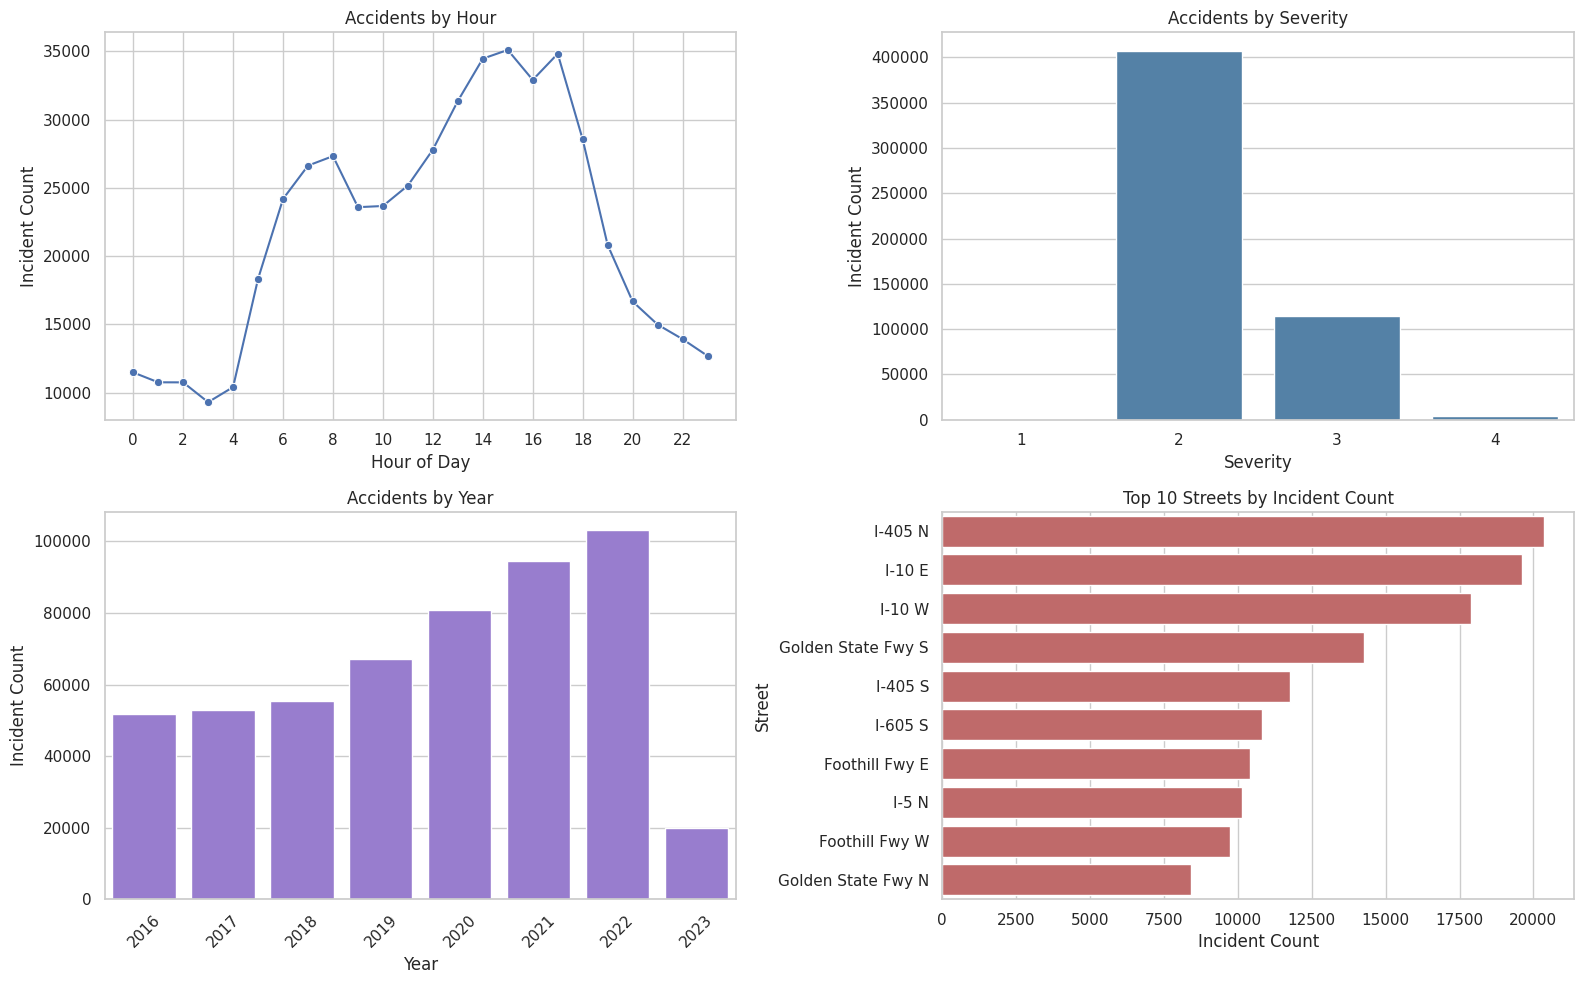

In [8]:
if not county_df.empty:
    sns.set_theme(style="whitegrid")

    county_df["Hour"]=county_df["Start_Time"].dt.hour
    county_df["Year"]=county_df["Start_Time"].dt.year
    county_df["Month"]=county_df["Start_Time"].dt.month
    county_df["Weekday"]=county_df["Start_Time"].dt.day_name()

    fig, axes=plt.subplots(2, 2, figsize=(16, 10))
    hourly=county_df.groupby("Hour").size().reindex(range(24), fill_value=0)
    sns.lineplot(x=hourly.index, y=hourly.values,marker="o", ax=axes[0, 0])
    axes[0, 0].set_title("Accidents by Hour")
    axes[0, 0].set_xlabel("Hour of Day")
    axes[0, 0].set_ylabel("Incident Count")
    axes[0, 0].set_xticks(range(0, 24, 2))

    severity=county_df["Severity"].value_counts().sort_index()
    sns.barplot(x=severity.index.astype(str), y=severity.values, color="steelblue",ax=axes[0, 1])
    axes[0, 1].set_title("Accidents by Severity")
    axes[0, 1].set_xlabel("Severity")
    axes[0, 1].set_ylabel("Incident Count")

    yearly=county_df.groupby("Year").size()
    sns.barplot(x=yearly.index.astype(str), y=yearly.values, color="mediumpurple", ax=axes[1, 0])
    axes[1, 0].set_title("Accidents by Year")
    axes[1, 0].set_xlabel("Year")
    axes[1, 0].set_ylabel("Incident Count")
    axes[1, 0].tick_params(axis="x", rotation=45)

    top_streets=county_df["Street"].value_counts().head(10)

    sns.barplot(x=top_streets.values, y=top_streets.index.astype(str), color="indianred", ax=axes[1, 1])
    axes[1, 1].set_title("Top 10 Streets by Incident Count")
    axes[1, 1].set_xlabel("Incident Count")
    axes[1, 1].set_ylabel("Street")

    plt.tight_layout()
    plt.show()
